In [17]:
# Import niezbędnych modułów
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, auc, recall_score, precision_score
from sklearn.ensemble import RandomForestClassifier

# Konfiguracja stylu wykresów
sns.set_style("whitegrid")
%matplotlib inline

In [18]:
# Import danych [cite: 16]
# Wczytujemy dane bankowe; separatorem w tym zbiorze jest średnik.
df = pd.read_csv('bank-full.csv', sep=';')
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [19]:
# Kodowanie zmiennych kategorycznych [cite: 16]
print('Converting categorical variables to numeric...')

# Mapowanie zmiennej celu 'y' (yes/no) na wartości binarne (1/0)
df['y'] = df['y'].map({'yes': 1, 'no': 0})

categorical_columns = ['job', 'marital', 'education', 'default', 'housing',
                       'loan', 'contact', 'day', 'month', 'campaign',
                       'previous', 'poutcome']

for c in categorical_columns:
    df[c] = df[c].astype('category')
    df[c] = df[c].cat.codes

df.head()

Converting categorical variables to numeric...


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,4,1,2,0,2143,1,0,2,4,8,261,0,-1,0,3,0
1,44,9,2,1,0,29,1,0,2,4,8,151,0,-1,0,3,0
2,33,2,1,1,0,2,1,1,2,4,8,76,0,-1,0,3,0
3,47,1,1,3,0,1506,1,0,2,4,8,92,0,-1,0,3,0
4,33,11,2,3,0,1,0,0,2,4,8,198,0,-1,0,3,0


In [20]:
train_df, test_df = train_test_split(df, test_size=0.25, random_state=1984)

train_y = train_df['y']
test_y = test_df['y']

train_x = train_df.drop(['y'], axis=1)
test_x = test_df.drop(['y'], axis=1)

In [21]:

model1 = RandomForestClassifier(max_depth=4, n_estimators=20, random_state=42)
model1.fit(train_x, train_y)

model2 = RandomForestClassifier(max_depth=12, n_estimators=120, random_state=42)
model2.fit(train_x, train_y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",120
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [22]:
pred1 = model1.predict_proba(test_x)
pred2 = model2.predict_proba(test_x)

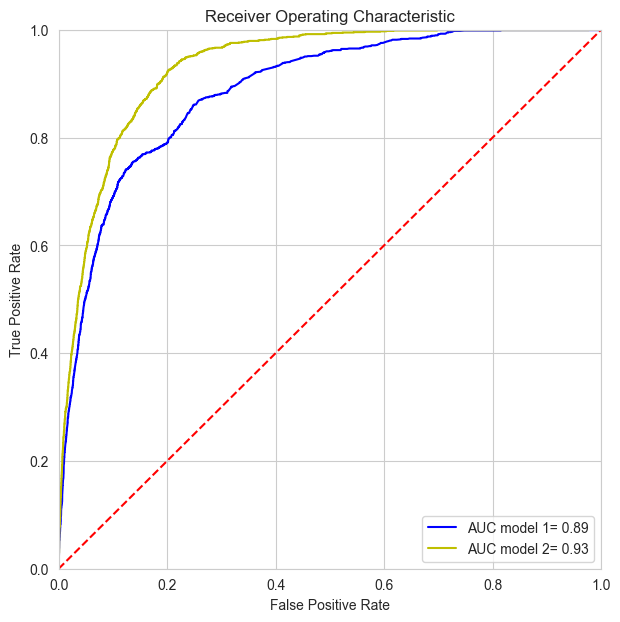

In [23]:

fpr1, tpr1, threshold1 = roc_curve(test_y, pred1[:, 1])
roc_auc1 = auc(fpr1, tpr1)

fpr2, tpr2, threshold2 = roc_curve(test_y, pred2[:, 1])
roc_auc2 = auc(fpr2, tpr2)

plt.figure(figsize=(7, 7))
plt.title('Receiver Operating Characteristic')
plt.plot(fpr1, tpr1, 'b', label='AUC model 1= %0.2f' % roc_auc1)
plt.plot(fpr2, tpr2, 'y', label='AUC model 2= %0.2f' % roc_auc2)
plt.legend(loc='lower right')
plt.plot([0, 1], [0, 1], 'r--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

In [24]:

def plot_custom_metrics(y_true, y_probas, model_name="Model"):
    y_true = np.array(y_true)
    y_probas = np.array(y_probas)
    idx = np.argsort(y_probas)[::-1]
    y_true_sorted = y_true[idx]
    
    gains = np.cumsum(y_true_sorted) / np.sum(y_true)
    gains = np.insert(gains, 0, 0)
    percentages = np.linspace(0, 1, len(gains))
    
    lift = (np.cumsum(y_true_sorted) / np.arange(1, len(y_true) + 1)) / (np.sum(y_true) / len(y_true))
    
    sns.set_style("whitegrid")
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    
    ax1.plot(percentages, gains, lw=3, color='royalblue', label=model_name)
    ax1.plot([0, 1], [0, 1], 'k--', lw=2, label='Baseline')
    ax1.set_title(f'Cumulative Gains Curve - {model_name}')
    ax1.set_xlabel('Percentage of sample')
    ax1.set_ylabel('Gain')
    ax1.legend()
    
    ax2.plot(percentages[1:], lift, lw=3, color='darkorange', label=model_name)
    ax2.axhline(y=1, color='black', linestyle='--', lw=2, label='Baseline')
    ax2.set_title(f'Lift Curve - {model_name}')
    ax2.set_xlabel('Percentage of sample')
    ax2.set_ylabel('Lift')
    ax2.legend()
    
    plt.tight_layout()
    plt.show()

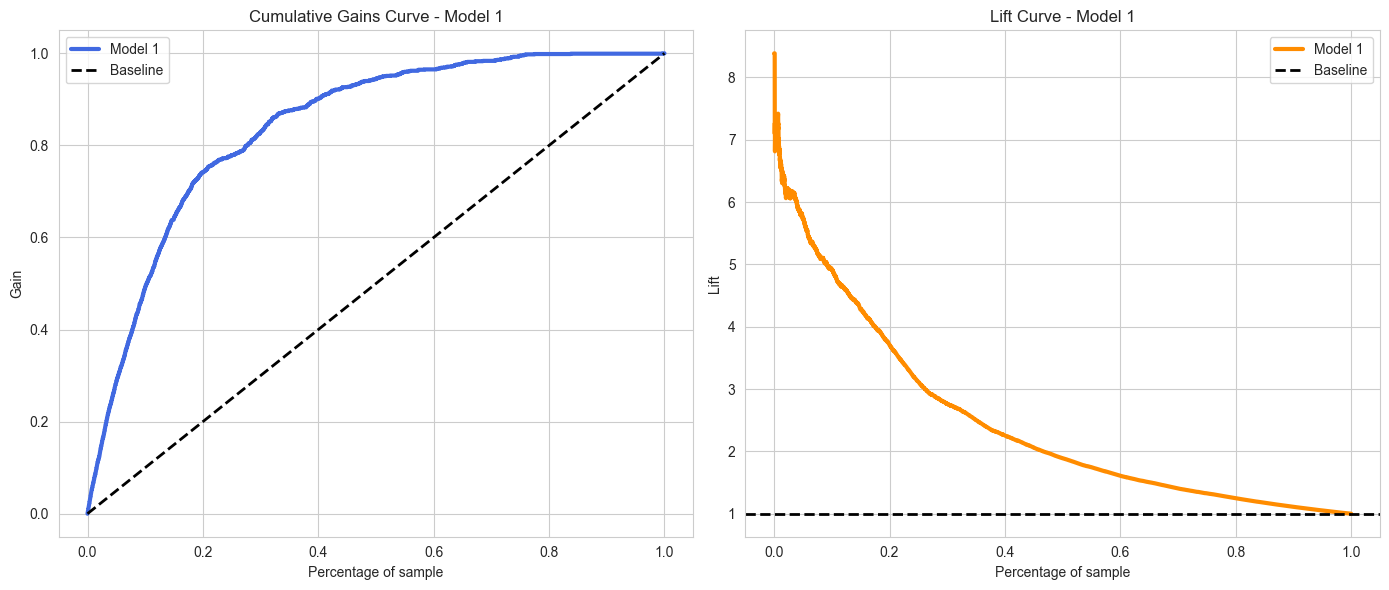

In [25]:
# Wywołanie wizualizacji dla Modelu 1 [cite: 19]
plot_custom_metrics(test_y, pred1[:, 1], "Model 1")

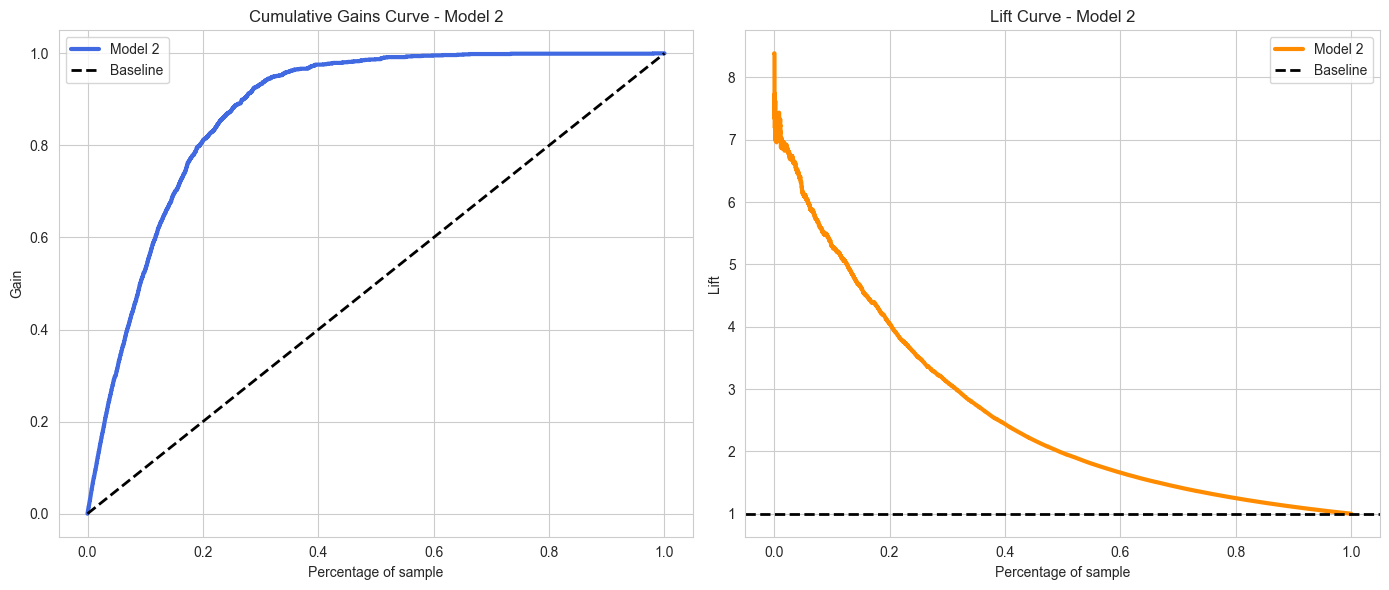

In [26]:
# Wywołanie wizualizacji dla Modelu 2 [cite: 20]
plot_custom_metrics(test_y, pred2[:, 1], "Model 2")